# CNN-Based Aftershock Prediction Using Spatial Context Windows
## SE4050 Deep Learning Assignment - California Earthquakes

**Objective**: Train CNNs to predict aftershock triggering by analyzing **spatial context** around each earthquake.

### Task Overview

**Input:** 32Ã—32 spatial grid centered on each earthquake with 3 channels:
- Channel 0: Earthquake density (count per cell)
- Channel 1: Average magnitude per cell
- Channel 2: Recency/time decay (recent earthquakes weighted higher)

**Output:** Binary classification
- Class 0: Does not trigger aftershocks
- Class 1: Triggers aftershocks (within 7 days, 50km radius)

**Why CNNs for Aftershock Prediction?**
- Learn spatial patterns of stress accumulation
- Detect clustered seismic activity around earthquake
- Identify high-risk spatial configurations
- Directly comparable to DNN/LSTM/GNN (same task!)

**Comparison with Other Models:**
- **DNN**: 28 tabular features (no spatial structure)
- **LSTM**: Temporal sequences of 10 earthquakes
- **GNN**: Graph with k-NN spatial + temporal edges
- **CNN**: Spatial grid showing neighborhood around each earthquake

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)
import warnings
import os
warnings.filterwarnings('ignore')

import sys
sys.path.append('../')
from models.cnn import AftershockCNN, AftershockCNN_Shallow, AftershockCNN_Deep

torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


## 1. Load Pre-Computed CNN Aftershock Data

Load the spatial context grids created in the feature engineering notebook.

In [ ]:
print("Loading CNN aftershock data from feature engineering...")

# Loading pre-computed grids
X_train = np.load('../data/processed/model_ready/X_train_cnn_aftershock.npy')
y_train = np.load('../data/processed/model_ready/y_train_cnn_aftershock.npy')
X_val = np.load('../data/processed/model_ready/X_val_cnn_aftershock.npy')
y_val = np.load('../data/processed/model_ready/y_val_cnn_aftershock.npy')
X_test = np.load('../data/processed/model_ready/X_test_cnn_aftershock.npy')
y_test = np.load('../data/processed/model_ready/y_test_cnn_aftershock.npy')

# Loading metadata
metadata = np.load('../data/processed/model_ready/cnn_aftershock_metadata.npy', allow_pickle=True).item()

print(f"\n✓ Data loaded successfully!")
print(f"\nData shapes:")
print(f"  Train: X={X_train.shape}, y={y_train.shape}")
print(f"  Val:   X={X_val.shape}, y={y_val.shape}")
print(f"  Test:  X={X_test.shape}, y={y_test.shape}")

print(f"\nGrid metadata:")
print(f"  Grid size: {metadata.get('grid_size', 32)}x{metadata.get('grid_size', 32)}")
print(f"  Channels: {X_train.shape[1]} (density, magnitude, recency)")
print(f"  Spatial radius: {metadata.get('spatial_radius_deg', 0.5)}° (~{metadata.get('spatial_radius_deg',
0.5)*111:.0f} km)")
print(f"  Lookback window: {metadata.get('lookback_indices', 50)} earthquakes")
print(f"  Normalization: {metadata.get('normalization', 'StandardScaler per channel')}")

print(f"\nClass distribution:")
if 'class_balance' in metadata:
    print(f"  Train: {(1-metadata['class_balance']['train_positive_rate'])*100:.1f}% {metadata['class_balance']['train_positive_rate']*100:.1f}%")
    print(f"  Val:   {(1-metadata['class_balance']['val_positive_rate'])*100:.1f}% {metadata['class_balance']['val_positive_rate']*100:.1f}%")
    print(f"  Test:  {(1-metadata['class_balance']['test_positive_rate'])*100:.1f}% {metadata['class_balance']['test_positive_rate']*100:.1f}%")
else:
    # Calculate from data
    train_pos_rate = y_train.mean()
    val_pos_rate = y_val.mean()
    test_pos_rate = y_test.mean()
    print(f"  Train: {(1-train_pos_rate)*100:.1f}% / {train_pos_rate*100:.1f}%")
    print(f"  Val:   {(1-val_pos_rate)*100:.1f}% / {val_pos_rate*100:.1f}%")
    print(f"  Test:  {(1-test_pos_rate)*100:.1f}% / {test_pos_rate*100:.1f}%")

Loading CNN aftershock data from feature engineering...

✓ Data loaded successfully!

Data shapes:
  Train: X=(3958, 3, 32, 32), y=(3958,)
  Val:   X=(859, 3, 32, 32), y=(859,)
  Test:  X=(860, 3, 32, 32), y=(860,)

Grid metadata:
  Grid size: 32x32
  Channels: 3 (density, magnitude, recency)
  Spatial radius: 0.5° (~56 km)
  Lookback window: 50 earthquakes
  Normalization: StandardScaler per channel

Class distribution:
  Train: 47.3% / 52.7%
  Val:   37.6% / 62.4%
  Test:  48.0% / 52.0%


## 2. Visualize Sample Grids

Visualize spatial context grids to understand what the CNN sees.

Visualizing sample spatial context grids...


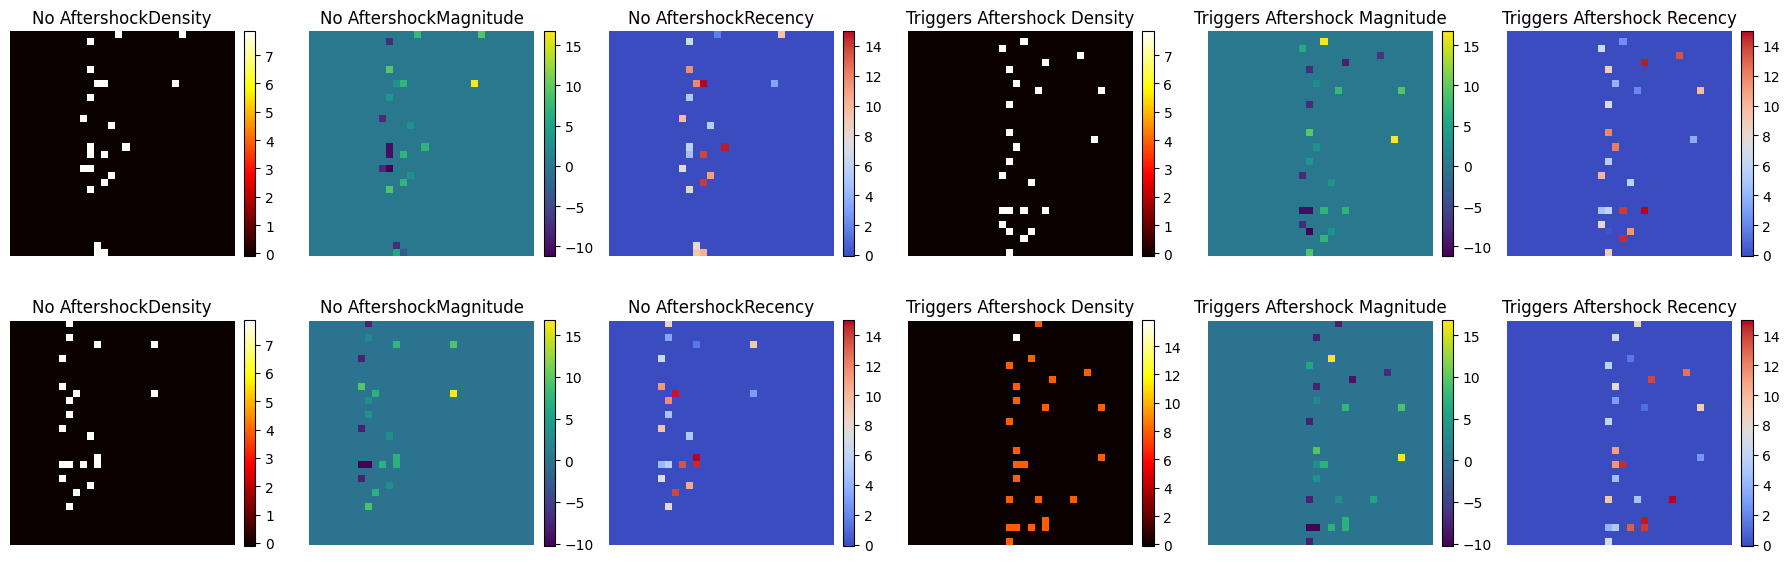

✓ Sample grids showing spatial context around earthquakes!


In [3]:
print("Visualizing sample spatial context grids...")

fig, axes = plt.subplots(2, 6, figsize=(18, 6))

# Get sample indices from each class
no_aftershock_idx = np.where(y_train == 0)[0][:2]
aftershock_idx = np.where(y_train == 1)[0][:2]

channel_names = ['Density', 'Magnitude', 'Recency']
cmaps = ['hot', 'viridis', 'coolwarm']

# Plot no aftershock examples
for i, idx in enumerate(no_aftershock_idx):
    for ch in range(3):
        ax = axes[i, ch]
        im = ax.imshow(X_train[idx, ch], cmap=cmaps[ch])
        ax.set_title(f'No Aftershock{channel_names[ch]}')
        ax.axis('off')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# Plot aftershock examples
for i, idx in enumerate(aftershock_idx):
    for ch in range(3):
        ax = axes[i, ch + 3]
        im = ax.imshow(X_train[idx, ch], cmap=cmaps[ch])
        ax.set_title(f'Triggers Aftershock {channel_names[ch]}')
        ax.axis('off')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
os.makedirs('../results/visualizations/cnn', exist_ok=True)
plt.savefig('../results/visualizations/cnn/aftershock_sample_grids.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ Sample grids showing spatial context around earthquakes!")

## 3. Prepare PyTorch DataLoaders

In [4]:
print("Preparing PyTorch DataLoaders...")

# Convert to PyTorch tensors
X_train_tensor = torch.FloatTensor(X_train)
y_train_tensor = torch.LongTensor(y_train)
X_val_tensor = torch.FloatTensor(X_val)
y_val_tensor = torch.LongTensor(y_val)
X_test_tensor = torch.FloatTensor(X_test)
y_test_tensor = torch.LongTensor(y_test)

print(f"✓ Tensors created:")
print(f"  Train: X={X_train_tensor.shape}, y={y_train_tensor.shape}")
print(f"  Val:   X={X_val_tensor.shape}, y={y_val_tensor.shape}")
print(f"  Test:  X={X_test_tensor.shape}, y={y_test_tensor.shape}")

# Create datasets
batch_size = 64
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"✓ DataLoaders created:")
print(f"  Batch size: {batch_size}")
print(f"  Train batches: {len(train_loader)}")
print(f"  Val batches: {len(val_loader)}")
print(f"  Test batches: {len(test_loader)}")

Preparing PyTorch DataLoaders...
✓ Tensors created:
  Train: X=torch.Size([3958, 3, 32, 32]), y=torch.Size([3958])
  Val:   X=torch.Size([859, 3, 32, 32]), y=torch.Size([859])
  Test:  X=torch.Size([860, 3, 32, 32]), y=torch.Size([860])
✓ DataLoaders created:
  Batch size: 64
  Train batches: 62
  Val batches: 14
  Test batches: 14


## 2. Visualize Sample Grids

Visualize spatial context grids to understand what the CNN sees.

Visualizing sample spatial context grids...


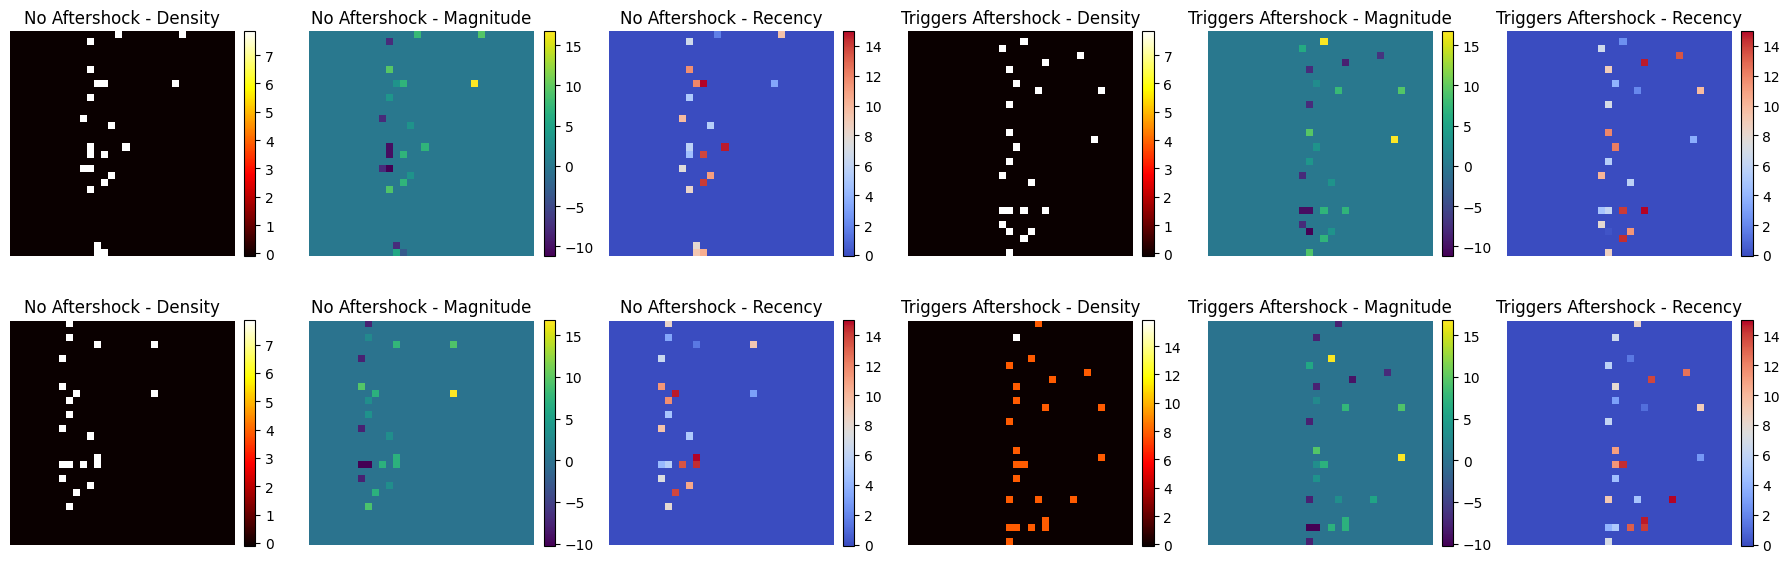

Sample grids showing spatial context around earthquakes!


In [5]:
print("Visualizing sample spatial context grids...")

fig, axes = plt.subplots(2, 6, figsize=(18, 6))

# Get sample indices from each class
no_aftershock_idx = np.where(y_train == 0)[0][:2]
aftershock_idx = np.where(y_train == 1)[0][:2]

channel_names = ['Density', 'Magnitude', 'Recency']
cmaps = ['hot', 'viridis', 'coolwarm']

# Plot no aftershock examples
for i, idx in enumerate(no_aftershock_idx):
    for ch in range(3):
        ax = axes[i, ch]
        im = ax.imshow(X_train[idx, ch], cmap=cmaps[ch])
        ax.set_title(f'No Aftershock - {channel_names[ch]}')
        ax.axis('off')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# Plot aftershock examples
for i, idx in enumerate(aftershock_idx):
    for ch in range(3):
        ax = axes[i, ch + 3]
        im = ax.imshow(X_train[idx, ch], cmap=cmaps[ch])
        ax.set_title(f'Triggers Aftershock - {channel_names[ch]}')
        ax.axis('off')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
os.makedirs('../results/visualizations/cnn', exist_ok=True)
plt.savefig('../results/visualizations/cnn/aftershock_sample_grids.png', dpi=150, bbox_inches='tight')
plt.show()

print("Sample grids showing spatial context around earthquakes!")

## 3. Prepare PyTorch DataLoaders

In [6]:
print("Preparing PyTorch DataLoaders...")

# Convert to PyTorch tensors
X_train_tensor = torch.FloatTensor(X_train)
y_train_tensor = torch.LongTensor(y_train)
X_val_tensor = torch.FloatTensor(X_val)
y_val_tensor = torch.LongTensor(y_val)
X_test_tensor = torch.FloatTensor(X_test)
y_test_tensor = torch.LongTensor(y_test)

print(f"Tensors created:")
print(f"  Train: X={X_train_tensor.shape}, y={y_train_tensor.shape}")
print(f"  Val:   X={X_val_tensor.shape}, y={y_val_tensor.shape}")
print(f"  Test:  X={X_test_tensor.shape}, y={y_test_tensor.shape}")

# Create datasets
batch_size = 64
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"DataLoaders created:")
print(f"  Batch size: {batch_size}")
print(f"  Train batches: {len(train_loader)}")
print(f"  Val batches: {len(val_loader)}")
print(f"  Test batches: {len(test_loader)}")

Preparing PyTorch DataLoaders...
Tensors created:
  Train: X=torch.Size([3958, 3, 32, 32]), y=torch.Size([3958])
  Val:   X=torch.Size([859, 3, 32, 32]), y=torch.Size([859])
  Test:  X=torch.Size([860, 3, 32, 32]), y=torch.Size([860])
DataLoaders created:
  Batch size: 64
  Train batches: 62
  Val batches: 14
  Test batches: 14


## 4. Calculate Class Weights

In [7]:
# Calculate class weights
class_counts = np.bincount(y_train.astype(int))
class_weights = 1.0 / class_counts
class_weights = class_weights / class_weights.sum()
class_weights_tensor = torch.FloatTensor(class_weights).to(device)

print(f"Class distribution (training):")
print(f"  Class 0 (no aftershock): {class_counts[0]} ({class_counts[0]/len(y_train)*100:.1f}%)")
print(f"  Class 1 (triggers aftershock): {class_counts[1]} ({class_counts[1]/len(y_train)*100:.1f}%)")
print(f"Class weights: {class_weights_tensor}")

Class distribution (training):
  Class 0 (no aftershock): 1871 (47.3%)
  Class 1 (triggers aftershock): 2087 (52.7%)
Class weights: tensor([0.5273, 0.4727])


## 5. Training and Evaluation Functions

In [8]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    all_preds = []
    all_labels = []
    
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())
    
    avg_loss = total_loss / len(loader)
    accuracy = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted')
    
    return avg_loss, accuracy, f1


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    all_preds = []
    all_labels = []
    all_probs = []
    
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            
            total_loss += loss.item()
            probs = torch.softmax(outputs, dim=1)
            preds = torch.argmax(outputs, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y_batch.cpu().numpy())
            all_probs.extend(probs[:, 1].cpu().numpy())
    
    avg_loss = total_loss / len(loader)
    accuracy = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, average='weighted', zero_division=0)
    recall = recall_score(all_labels, all_preds, average='weighted', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='weighted', zero_division=0)
    
    return avg_loss, accuracy, precision, recall, f1, all_preds, all_labels, all_probs


def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, 
                num_epochs, device, model_name):
    print(f"Training {model_name}...")
    
    best_val_f1 = 0
    best_epoch = 0
    patience = 15
    patience_counter = 0
    
    history = {
        'train_loss': [], 'train_acc': [], 'train_f1': [],
        'val_loss': [], 'val_acc': [], 'val_f1': []
    }
    
    for epoch in range(num_epochs):
        train_loss, train_acc, train_f1 = train_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc, val_prec, val_rec, val_f1, _, _, _ = evaluate(model, val_loader, criterion, device)
        scheduler.step(val_loss)
        
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['train_f1'].append(train_f1)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['val_f1'].append(val_f1)
        
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}]")
            print(f"  Train: Loss={train_loss:.4f}, Acc={train_acc:.4f}, F1={train_f1:.4f}")
            print(f"  Val:   Loss={val_loss:.4f}, Acc={val_acc:.4f}, F1={val_f1:.4f}")
        
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_epoch = epoch + 1
            patience_counter = 0
            os.makedirs('../models/saved/cnn', exist_ok=True)
            torch.save(model.state_dict(), f'../models/saved/cnn/{model_name}_best.pth')
        else:
            patience_counter += 1
        
        if patience_counter >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break
    
    print(f"Training complete! Best val F1: {best_val_f1:.4f} at epoch {best_epoch}")
    model.load_state_dict(torch.load(f'../models/saved/cnn/{model_name}_best.pth'))
    
    return model, history

print("Training functions defined")

Training functions defined


## 6. Train CNN Models

In [9]:
num_epochs = 100
learning_rate = 0.001

print("="*70)
print("TRAINING CNN MODELS FOR AFTERSHOCK PREDICTION")
print("="*70)
print(f"Hyperparameters:")
print(f"  Max epochs: {num_epochs}")
print(f"  Learning rate: {learning_rate}")
print(f"  Batch size: {batch_size}")
print(f"  Early stopping patience: 15")
print(f"  Device: {device}")

TRAINING CNN MODELS FOR AFTERSHOCK PREDICTION
Hyperparameters:
  Max epochs: 100
  Learning rate: 0.001
  Batch size: 64
  Early stopping patience: 15
  Device: cpu


### 6.1 Shallow CNN

In [10]:
print("="*70)
print("MODEL 1: SHALLOW CNN (Baseline)")
print("="*70)

model_shallow = AftershockCNN_Shallow(in_channels=3, num_classes=2, dropout=0.25).to(device)
criterion_shallow = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer_shallow = optim.Adam(model_shallow.parameters(), lr=learning_rate)
scheduler_shallow = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_shallow, mode='min', factor=0.5, patience=5
)

print(f"Model: Shallow CNN")
print(f"  Conv blocks: 2")
print(f"  Parameters: {sum(p.numel() for p in model_shallow.parameters()):,}")

model_shallow, history_shallow = train_model(
    model_shallow, train_loader, val_loader, criterion_shallow, 
    optimizer_shallow, scheduler_shallow, num_epochs, device, 'shallow_cnn_aftershock'
)

MODEL 1: SHALLOW CNN (Baseline)
Model: Shallow CNN
  Conv blocks: 2
  Parameters: 1,068,930
Training shallow_cnn_aftershock...
Epoch [1/100]
  Train: Loss=19.9680, Acc=0.5508, F1=0.5510
  Val:   Loss=3.6893, Acc=0.5006, F1=0.4978
Epoch [5/100]
  Train: Loss=0.6768, Acc=0.6104, F1=0.6082
  Val:   Loss=0.6784, Acc=0.5437, F1=0.5450
Epoch [10/100]
  Train: Loss=0.6450, Acc=0.6235, F1=0.6220
  Val:   Loss=0.6394, Acc=0.6217, F1=0.6264
Epoch [15/100]
  Train: Loss=0.6279, Acc=0.6339, F1=0.6286
  Val:   Loss=0.6480, Acc=0.6019, F1=0.6039
Early stopping at epoch 19
Training complete! Best val F1: 0.6390 at epoch 4


### 6.2 Standard CNN

In [11]:
print("="*70)
print("MODEL 2: STANDARD CNN (Main Model)")
print("="*70)

model_standard = AftershockCNN(in_channels=3, num_classes=2, dropout=0.3).to(device)
criterion_standard = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer_standard = optim.Adam(model_standard.parameters(), lr=learning_rate)
scheduler_standard = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_standard, mode='min', factor=0.5, patience=5)

print(f"Model: Standard CNN")
print(f"  Conv blocks: 4")
print(f"  Parameters: {sum(p.numel() for p in model_standard.parameters()):,}")

model_standard, history_standard = train_model(
    model_standard, train_loader, val_loader, criterion_standard, 
    optimizer_standard, scheduler_standard, num_epochs, device, 'standard_cnn_aftershock'
)

MODEL 2: STANDARD CNN (Main Model)
Model: Standard CNN
  Conv blocks: 4
  Parameters: 981,378
Training standard_cnn_aftershock...
Epoch [1/100]
  Train: Loss=3.9006, Acc=0.5460, F1=0.5437
  Val:   Loss=2.0245, Acc=0.5471, F1=0.5402
Epoch [5/100]
  Train: Loss=1.6070, Acc=0.5596, F1=0.5600
  Val:   Loss=0.7220, Acc=0.5949, F1=0.5829
Epoch [10/100]
  Train: Loss=1.0044, Acc=0.5728, F1=0.5727
  Val:   Loss=0.6447, Acc=0.6263, F1=0.6265
Epoch [15/100]
  Train: Loss=0.8461, Acc=0.5937, F1=0.5935
  Val:   Loss=0.6712, Acc=0.5553, F1=0.5511
Epoch [20/100]
  Train: Loss=0.7620, Acc=0.6081, F1=0.6066
  Val:   Loss=0.6706, Acc=0.5611, F1=0.5457
Epoch [25/100]
  Train: Loss=0.7586, Acc=0.6205, F1=0.6184
  Val:   Loss=0.6827, Acc=0.5378, F1=0.5253
Early stopping at epoch 25
Training complete! Best val F1: 0.6265 at epoch 10


### 6.3 Deep CNN

In [12]:
print("="*70)
print("MODEL 3: DEEP CNN (Residual)")
print("="*70)

model_deep = AftershockCNN_Deep(in_channels=3, num_classes=2, dropout=0.35).to(device)
criterion_deep = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer_deep = optim.Adam(model_deep.parameters(), lr=learning_rate)
scheduler_deep = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_deep, mode='min', factor=0.5, patience=5
)

print(f"Model: Deep CNN (Residual)")
print(f"  Residual blocks: 3")
print(f"  Parameters: {sum(p.numel() for p in model_deep.parameters()):,}")

model_deep, history_deep = train_model(
    model_deep, train_loader, val_loader, criterion_deep, 
    optimizer_deep, scheduler_deep, num_epochs, device, 'deep_cnn_aftershock'
)

MODEL 3: DEEP CNN (Residual)
Model: Deep CNN (Residual)
  Residual blocks: 3
  Parameters: 5,669,122
Training deep_cnn_aftershock...
Epoch [1/100]
  Train: Loss=6.2787, Acc=0.5445, F1=0.5430
  Val:   Loss=2.3640, Acc=0.5204, F1=0.5213
Epoch [5/100]
  Train: Loss=1.5230, Acc=0.5642, F1=0.5644
  Val:   Loss=0.6499, Acc=0.6263, F1=0.6157
Epoch [10/100]
  Train: Loss=0.9203, Acc=0.5755, F1=0.5757
  Val:   Loss=0.5602, Acc=0.6671, F1=0.6384
Epoch [15/100]
  Train: Loss=0.8190, Acc=0.5824, F1=0.5823
  Val:   Loss=0.6695, Acc=0.5541, F1=0.5272
Epoch [20/100]
  Train: Loss=0.7774, Acc=0.6081, F1=0.6075
  Val:   Loss=0.6989, Acc=0.4796, F1=0.4045
Epoch [25/100]
  Train: Loss=0.7152, Acc=0.6291, F1=0.6277
  Val:   Loss=0.7096, Acc=0.4563, F1=0.3682
Early stopping at epoch 29
Training complete! Best val F1: 0.6468 at epoch 14


## 7. Plot Training History

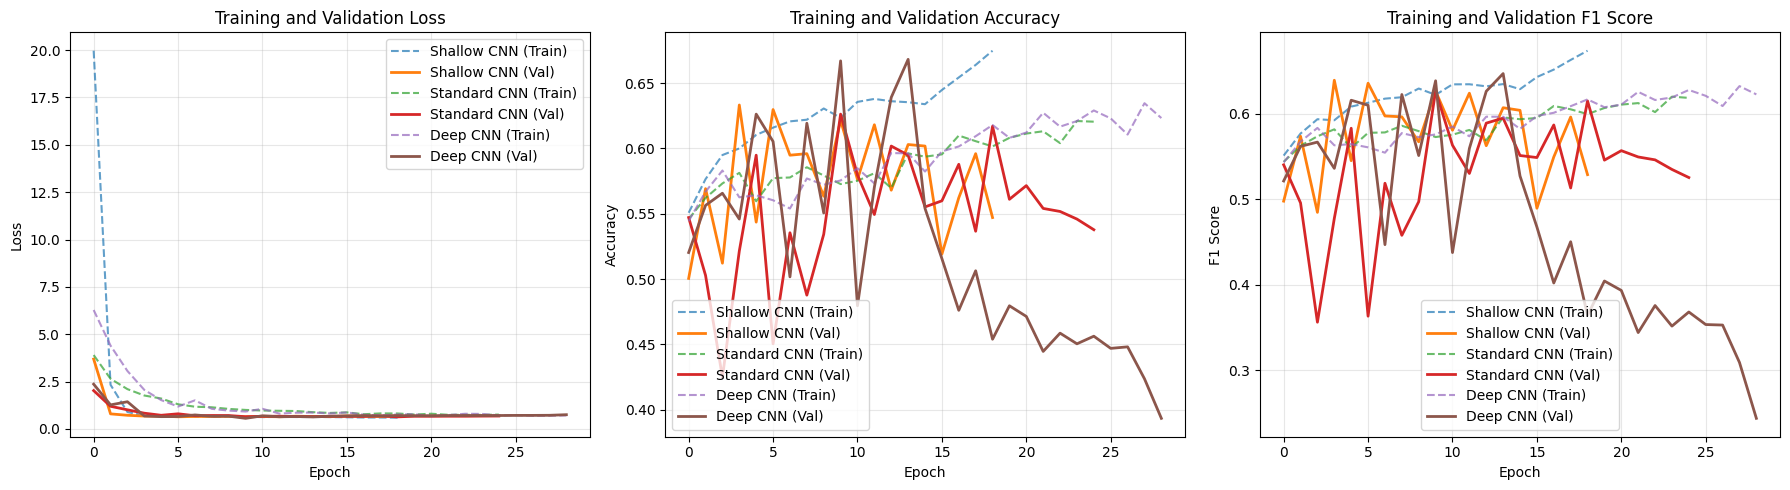

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

histories = {
    'Shallow CNN': history_shallow,
    'Standard CNN': history_standard,
    'Deep CNN': history_deep
}

# Loss
ax = axes[0]
for name, hist in histories.items():
    ax.plot(hist['train_loss'], label=f'{name} (Train)', linestyle='--', alpha=0.7)
    ax.plot(hist['val_loss'], label=f'{name} (Val)', linewidth=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('Training and Validation Loss')
ax.legend()
ax.grid(True, alpha=0.3)

# Accuracy
ax = axes[1]
for name, hist in histories.items():
    ax.plot(hist['train_acc'], label=f'{name} (Train)', linestyle='--', alpha=0.7)
    ax.plot(hist['val_acc'], label=f'{name} (Val)', linewidth=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy')
ax.set_title('Training and Validation Accuracy')
ax.legend()
ax.grid(True, alpha=0.3)

# F1 Score
ax = axes[2]
for name, hist in histories.items():
    ax.plot(hist['train_f1'], label=f'{name} (Train)', linestyle='--', alpha=0.7)
    ax.plot(hist['val_f1'], label=f'{name} (Val)', linewidth=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('F1 Score')
ax.set_title('Training and Validation F1 Score')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../results/visualizations/cnn/aftershock_training_history.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Evaluate on Test Set

In [14]:
print("="*70)
print("EVALUATING ON TEST SET")
print("="*70)

models = {
    'Shallow CNN': (model_shallow, criterion_shallow),
    'Standard CNN': (model_standard, criterion_standard),
    'Deep CNN': (model_deep, criterion_deep)
}

test_results = {}

for name, (model, criterion) in models.items():
    print(f"{name}:")
    test_loss, test_acc, test_prec, test_rec, test_f1, preds, labels, probs = evaluate(
        model, test_loader, criterion, device
    )
    
    report = classification_report(labels, preds, target_names=['No Aftershock', 'Triggers Aftershock'], 
                                   output_dict=True, zero_division=0)
    roc_auc = roc_auc_score(labels, probs)
    
    print(f"  Accuracy: {test_acc:.4f}")
    print(f"  Precision: {test_prec:.4f}")
    print(f"  Recall: {test_rec:.4f}")
    print(f"  F1 Score: {test_f1:.4f}")
    print(f"  ROC-AUC: {roc_auc:.4f}")
    
    test_results[name] = {
        'loss': test_loss, 'accuracy': test_acc, 'precision': test_prec,
        'recall': test_rec, 'f1': test_f1, 'roc_auc': roc_auc,
        'predictions': preds, 'labels': labels, 'probs': probs
    }

EVALUATING ON TEST SET
Shallow CNN:
  Accuracy: 0.5570
  Precision: 0.5730
  Recall: 0.5570
  F1 Score: 0.5448
  ROC-AUC: 0.5708
Standard CNN:
  Accuracy: 0.5419
  Precision: 0.5872
  Recall: 0.5419
  F1 Score: 0.4969
  ROC-AUC: 0.6012
Deep CNN:
  Accuracy: 0.5535
  Precision: 0.5522
  Recall: 0.5535
  F1 Score: 0.5449
  ROC-AUC: 0.5819


## 9. Confusion Matrices

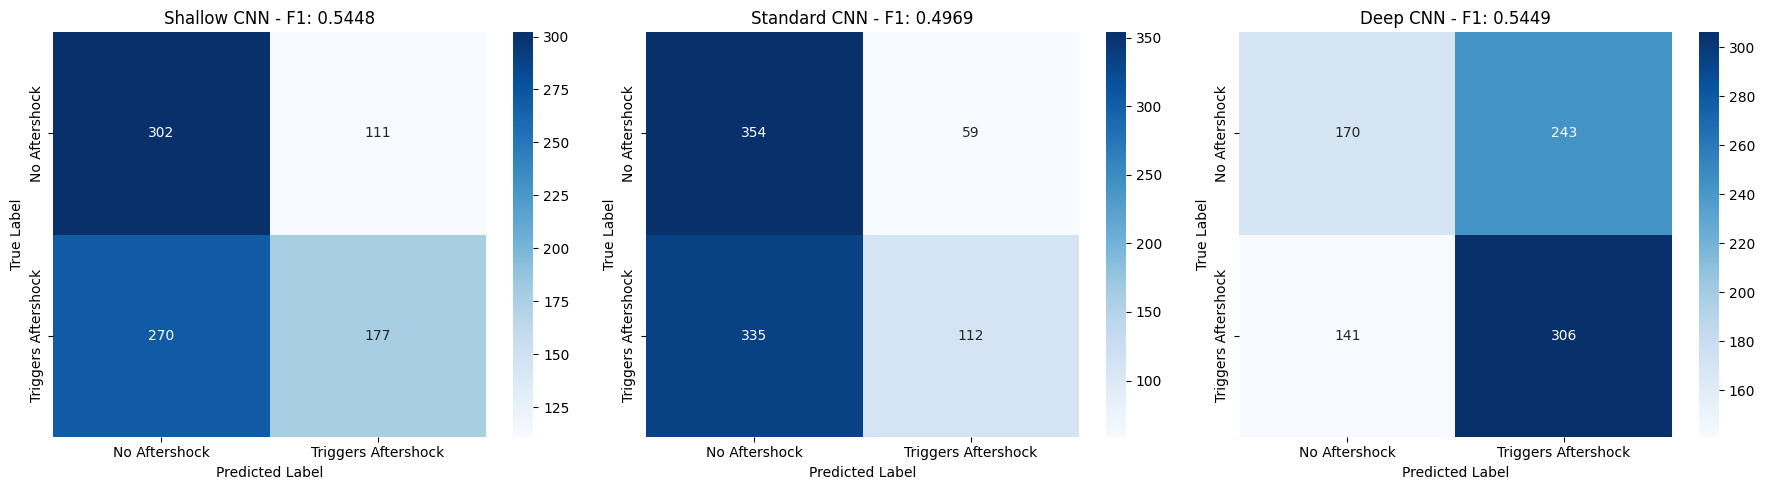

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, results) in enumerate(test_results.items()):
    cm = confusion_matrix(results['labels'], results['predictions'])
    
    ax = axes[idx]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No Aftershock', 'Triggers Aftershock'],
                yticklabels=['No Aftershock', 'Triggers Aftershock'])
    ax.set_ylabel('True Label')
    ax.set_xlabel('Predicted Label')
    ax.set_title(f'{name} - F1: {results["f1"]:.4f}')

plt.tight_layout()
plt.savefig('../results/visualizations/cnn/aftershock_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. ROC Curves

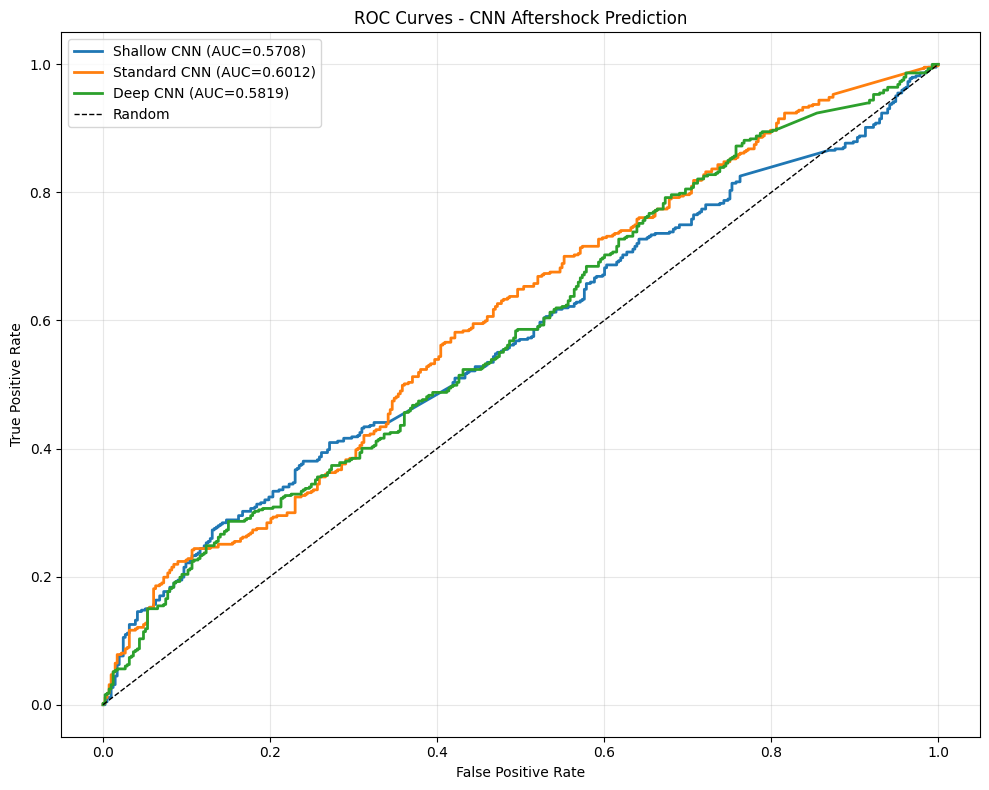

In [16]:
plt.figure(figsize=(10, 8))

for name, results in test_results.items():
    fpr, tpr, _ = roc_curve(results['labels'], results['probs'])
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC={results['roc_auc']:.4f})")

plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - CNN Aftershock Prediction')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../results/visualizations/cnn/aftershock_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Model Comparison Summary

In [17]:
print("="*70)
print("FINAL MODEL COMPARISON")
print("="*70)

comparison_data = []
for name, results in test_results.items():
    comparison_data.append({
        'Model': name,
        'Accuracy': results['accuracy'],
        'Precision': results['precision'],
        'Recall': results['recall'],
        'F1 Score': results['f1'],
        'ROC-AUC': results['roc_auc']
    })

comparison_df = pd.DataFrame(comparison_data)
comparison_df = comparison_df.sort_values('F1 Score', ascending=False)

print(comparison_df.to_string(index=False))

os.makedirs('../results/cnn', exist_ok=True)
comparison_df.to_csv('../results/cnn/aftershock_model_comparison.csv', index=False)

best_model_name = comparison_df.iloc[0]['Model']
best_f1 = comparison_df.iloc[0]['F1 Score']

print(f"Best Model: {best_model_name}")
print(f"F1 Score: {best_f1:.4f}")

FINAL MODEL COMPARISON
       Model  Accuracy  Precision   Recall  F1 Score  ROC-AUC
    Deep CNN  0.553488   0.552213 0.553488  0.544899 0.581932
 Shallow CNN  0.556977   0.572990 0.556977  0.544815 0.570784
Standard CNN  0.541860   0.587170 0.541860  0.496929 0.601199
Best Model: Deep CNN
F1 Score: 0.5449


## 12. Summary

In [18]:
print("="*70)
print("CNN AFTERSHOCK PREDICTION - COMPLETE")
print("="*70)

print("Task: Binary classification - predict if earthquake triggers aftershocks")
print(f"Input: 32x32 spatial context grids with 3 channels")
print(f"  - Density, Magnitude, Recency")
print(f"  - Spatial radius: {metadata['spatial_radius_deg']} degrees (~55km)")
print(f"  - Lookback: {metadata['lookback_indices']} earthquakes")

print(f"Best Model: {best_model_name}")
print(f"  F1 Score: {best_f1:.4f}")

print("Saved artifacts:")
print("  - Models: ../models/saved/cnn/")
print("  - Visualizations: ../results/visualizations/cnn/")
print("  - Results: ../results/cnn/aftershock_model_comparison.csv")

print("CNN models use spatial patterns to predict aftershock triggering!")
print("Compare with DNN, LSTM, and GNN results for complete analysis.")

CNN AFTERSHOCK PREDICTION - COMPLETE
Task: Binary classification - predict if earthquake triggers aftershocks
Input: 32x32 spatial context grids with 3 channels
  - Density, Magnitude, Recency
  - Spatial radius: 0.5 degrees (~55km)
  - Lookback: 50 earthquakes
Best Model: Deep CNN
  F1 Score: 0.5449
Saved artifacts:
  - Models: ../models/saved/cnn/
  - Visualizations: ../results/visualizations/cnn/
  - Results: ../results/cnn/aftershock_model_comparison.csv
CNN models use spatial patterns to predict aftershock triggering!
Compare with DNN, LSTM, and GNN results for complete analysis.
